In [330]:
import numpy as np
import math
import matplotlib.pyplot as plt
from scipy import signal

In [331]:
def ler_arquivo_hex(arquivo):
    valores = []
    
    with open(arquivo, 'r') as arquivo:
        for linha in arquivo:
            linha = linha.strip() # Remove espaços e quebras de linha
            if not linha:
                continue
            valor_inteiro = int(linha, 16) #le em hexa e converte pra int
            #se tiver numeros negativos
            if valor_inteiro >= 32768:
                valor_inteiro -= 65536

            valores.append(valor_inteiro)

    vetor_x = np.array(valores) / 32767.0 #converte p array do numpy e volta pra -1 a 1

    return vetor_x

In [332]:
def lms(w, x, e):
    #mu = 10**-6
    mu = 0.001
    n = len(w) 

    for i in range (n):
        w[i] = w[i] + mu * e * x[i]

    return w

In [333]:
def filtro(w, x):
    N = len(w)
    soma = 0
    for j in range(N):
        soma = soma + w[j] * x[j]
    
    return soma 

In [334]:
def filtro_iir(sinal, frequencia_corte, fs):
    ordem = 2
    sos = signal.butter(N=ordem, Wn=frequencia_corte, btype='lowpass', analog=False, fs=fs, output='sos')

    # Usar sosfilt em vez de sosfiltfilt para manter a causalidade do sistema
    sinal_filtrado = signal.sosfilt(sos, sinal)
    
    return sinal_filtrado

In [335]:

fc_hertz = 1000
fs = 8000
m = 25

X = ler_arquivo_hex('ruido_branco.hex')

E = np.zeros(len(X))
D_save = np.zeros(len(X))
Y_save = np.zeros(len(X))

W = np.zeros(m)

janela_x = np.zeros(m)

In [336]:
D_total = filtro_iir(X, fc_hertz, fs)

for i in range(len(X)):
    for j in range(m-1, 0, -1):
        janela_x[j] = janela_x[j-1]
    janela_x[0] = X[i]

    D = D_total[i] 
    Y = filtro(W, janela_x)

    D_save[i] = D
    Y_save[i] = Y
    e = D - Y
    E[i] = e

    W = lms(W, janela_x, e)

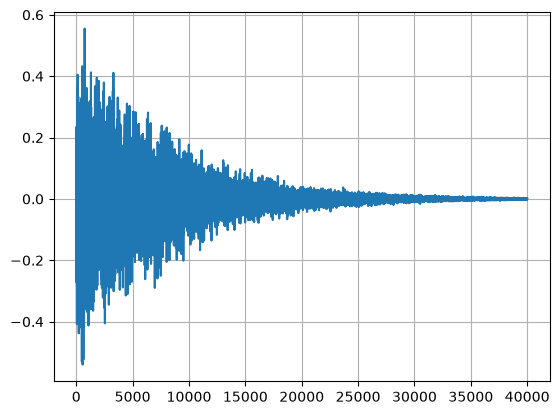

In [337]:
plt.plot(E)

plt.grid()

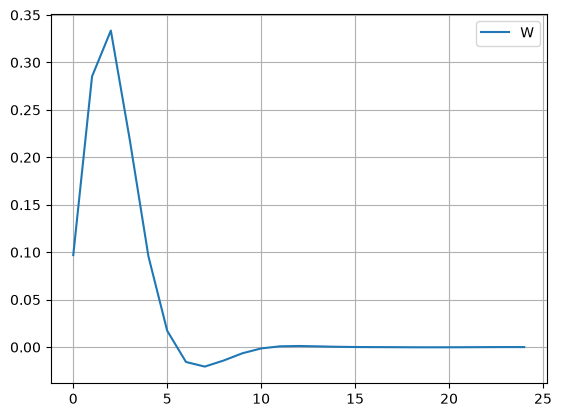

In [338]:
plt.plot(W, label='W')
#plt.plot(D_save, label='T')

plt.legend()
plt.grid()

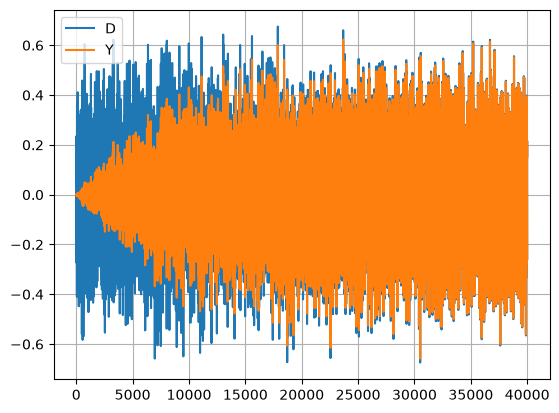

In [339]:
plt.plot(D_save, label='D')
plt.plot(Y_save, label='Y')

plt.legend()
plt.grid()